In [12]:
# 그래프 관련
import matplotlib.pyplot as plt
import matplotlib
matplotlib.rcParams['font.family'] = 'Malgun Gothic'
# matplotlib.rcParams['font.family'] = 'AppleGothic'
matplotlib.rcParams['axes.unicode_minus']=False

import pandas as pd
import numpy as np

# 머신러닝 관련
from sklearn import svm,metrics
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier, KNeighborsRegressor
from sklearn.linear_model import LinearRegression, Ridge, Lasso, SGDClassifier
from sklearn.preprocessing import StandardScaler, PolynomialFeatures, OneHotEncoder
from sklearn.metrics import mean_absolute_error 
from sklearn.linear_model import LogisticRegression
from scipy.special import expit
from scipy.special import softmax

In [22]:
wine = pd.read_csv('data/wine.csv')
wine.head(3)

,alcohol,sugar,pH,class
0,9.4,1.9,3.51,0.0
1,9.8,2.6,3.20,0.0
2,9.8,2.3,3.26,0.0


In [14]:
data = wine[wine.columns[:3]].values
data[:2]
label = wine['class'].values

In [15]:
train_data,test_data,train_label,test_label = train_test_split(data,label)

In [16]:
# StandartScaler 정규화
ss = StandardScaler()
ss.fit(train_data)
train_scaled = ss.transform(train_data)
test_scaled = ss.transform(test_data)

In [17]:
sgc = SGDClassifier(loss='log_loss',random_state=42,verbose=1)
train_score = []
test_score = []
# classes = train_label.unique()
classes = np.unique(train_label)

for i in range(300):
    sgc.partial_fit(train_scaled, train_label, classes=classes)
    score = sgc.score(train_scaled, train_label)
    score2 = sgc.score(test_scaled, test_label)
    train_score.append(score)
    test_score.append(score2)

-- Epoch 1
Norm: 4.75, NNZs: 3, Bias: 3.242166, T: 4872, Avg. loss: 1.632235, Objective: 1.638484
Total training time: 0.00 seconds.
-- Epoch 1
Norm: 2.83, NNZs: 3, Bias: 2.409094, T: 4872, Avg. loss: 0.699501, Objective: 0.700261
Total training time: 0.00 seconds.
-- Epoch 1
Norm: 2.27, NNZs: 3, Bias: 2.317942, T: 4872, Avg. loss: 0.559363, Objective: 0.559807
Total training time: 0.00 seconds.
-- Epoch 1
Norm: 2.03, NNZs: 3, Bias: 2.307332, T: 4872, Avg. loss: 0.510001, Objective: 0.510349
Total training time: 0.00 seconds.
-- Epoch 1
Norm: 1.91, NNZs: 3, Bias: 2.297621, T: 4872, Avg. loss: 0.485592, Objective: 0.485897
Total training time: 0.00 seconds.
-- Epoch 1
Norm: 1.84, NNZs: 3, Bias: 2.283895, T: 4872, Avg. loss: 0.471225, Objective: 0.471504
Total training time: 0.00 seconds.
-- Epoch 1
Norm: 1.80, NNZs: 3, Bias: 2.268088, T: 4872, Avg. loss: 0.461854, Objective: 0.462117
Total training time: 0.00 seconds.
-- Epoch 1
Norm: 1.78, NNZs: 3, Bias: 2.251283, T: 4872, Avg. loss: 0

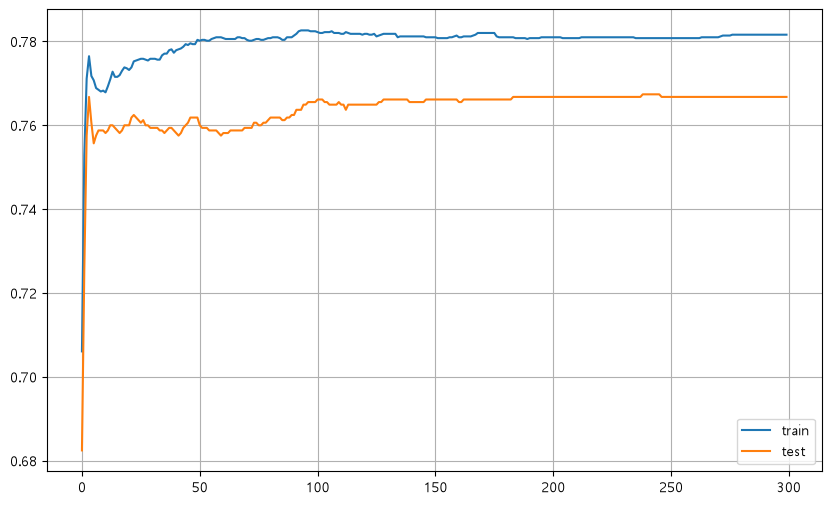

In [19]:
plt.figure(figsize=(10,6))
plt.plot(train_score)
plt.plot(test_score)
plt.grid()
plt.legend(['train', 'test'])
plt.show()

In [21]:
input1 = input('와인의 alcohol,sugar,pH 입력(예:9.4,1.9,3.51 / 12.8,1.1,3.34)')
input_data = [[float(x) for x in input1.split(',')]]

# 훈련 때 사용한 ss(StandardScaler)로 반드시 스케일링
input_scaled = ss.transform(input_data)

# 예측 클래스 및 확률 계산
pred_wine = sgc.predict(input_scaled)[0]          # 예측된 생선 이름 (예: 'Bream')
pred_proba = sgc.predict_proba(input_scaled)[0]      # 각 클래스별 확률 배열 (예: [0.9976, 0.0024])

wine1 = "White wine(1)" if pred_wine == 1 else "Red wine(0)"
# 가장 높은 확률(예측된 와인의 확률) 추출 후 백분율 변환
max_proba = np.max(pred_proba) * 100

print(f'와인확률 : {wine1} ({max_proba:.2f}%)')

와인확률 : Red wine(0) (75.04%)
